# Natural asymmetry of the ICBM 152 template

The volume behind `mni152.py` is an ICBM 2009 nonlinear **asymmetric** T1. Asymmetric means the average was allowed to keep left–right differences. This notebook is a few attempts at seeing those differences, and a reading of the view that works.

It uses the 1 mm 2009c file (`mni_icbm152_t1_tal_nlin_asym_09c`). The 0.5 mm 2009b volume is the same anatomy, but its grid sits half a millimetre off x = 0, so reversing the x axis is not a true mirror.

The 152 contributors were mostly right-handed young adults. What shows up here is that cohort's average, which is milder than a typical single brain.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter

# Blur width for the shape map. 0 mm is sulcal edges. 8 mm is the petalia.
# 14 mm starts to smear the frontal and occipital lobes together.
SIGMA_MM = 8.0

PATH = Path("mni_icbm152_t1_tal_nlin_asym_09c.nii") / "mni_icbm152_t1_tal_nlin_asym_09c.nii"
if not PATH.exists():
    raise FileNotFoundError(f"run this notebook from the repo root; missing {PATH}")

img = nib.load(PATH)
vol = np.asarray(img.dataobj, dtype=np.float32)
affine = img.affine
zooms = np.array(img.header.get_zooms()[:3], dtype=float)

if not np.allclose(affine[:3, :3], np.diag(zooms)):
    raise ValueError("expected a diagonal RAS affine")

# world = scale * index + offset.  The partner across the midline has x negated:
# scale * i_src + offset = -(scale * i + offset).
def mirror_lr(volume):
    n = volume.shape[0]
    i = np.arange(n)
    src = -i - 2 * affine[0, 3] / affine[0, 0]
    src_i = np.rint(src).astype(int)
    if not np.allclose(src, src_i) or src_i.min() < 0 or src_i.max() >= n:
        raise ValueError("midline is not centered on this grid")
    return volume[src_i]

def index_of(mm, axis):
    return int(np.rint((mm - affine[axis, 3]) / affine[axis, axis]))

def axial(volume, z_mm):
    return np.rot90(volume[:, :, index_of(z_mm, 2)])

def coronal(volume, y_mm):
    return np.rot90(volume[:, index_of(y_mm, 1), :])

def sagittal_crop(volume, x_mm, y0=-70, y1=45, z0=-25, z1=60):
    x = index_of(x_mm, 0)
    ys = slice(index_of(y0, 1), index_of(y1, 1))
    zs = slice(index_of(z0, 2), index_of(z1, 2))
    return np.rot90(volume[x, ys, zs])

x = (np.arange(vol.shape[0]) * affine[0, 0] + affine[0, 3])[:, None, None]
y = (np.arange(vol.shape[1]) * affine[1, 1] + affine[1, 3])[None, :, None]
z = (np.arange(vol.shape[2]) * affine[2, 2] + affine[2, 3])[None, None, :]

# Loose mask for the overlay, so background stays neutral.
head = gaussian_filter((vol > 15).astype(np.float32), 1.0) > 0.5
# Tighter mask for the numbers, so scalp and partial-volume rim do not dominate.
tissue = vol > 40

mirrored = mirror_lr(vol)
blur = gaussian_filter(vol, SIGMA_MM / zooms)
diff = blur - mirror_lr(blur)
clim = float(np.percentile(np.abs(diff[head]), 98))

print(
    f"shape {vol.shape}  zooms {zooms[0]:.0f} x {zooms[1]:.0f} x {zooms[2]:.0f} mm"
    f"  intensity {vol.min():.0f}..{vol.max():.0f}"
)
print(f"midline voxel i={index_of(0, 0)} is world x={affine[0, 0] * index_of(0, 0) + affine[0, 3]:.1f} mm")
print(f"SIGMA_MM={SIGMA_MM}  color limit ±{clim:.1f} (98th percentile inside the head)")

def pole_y(z_mm, x_lo, x_hi):
    sl = vol[:, :, index_of(z_mm, 2)] > 40
    cols = (x[:, 0, 0] >= x_lo) & (x[:, 0, 0] < x_hi)
    good = sl[cols].sum(axis=0) >= 3
    ys = y[0, :, 0][good]
    return float(ys.min()), float(ys.max())

for side, x_lo, x_hi in (("left", -55, -15), ("right", 15, 55)):
    y_back, y_front = pole_y(8, x_lo, x_hi)
    print(f"z=8 mm  {side:5}  backmost y={y_back:.0f}  frontmost y={y_front:.0f}")

shape (193, 229, 193)  zooms 1 x 1 x 1 mm  intensity -0..99
midline voxel i=96 is world x=0.0 mm
SIGMA_MM=8.0  color limit ±3.6 (98th percentile inside the head)
z=8 mm  left   backmost y=-117  frontmost y=84
z=8 mm  right  backmost y=-117  frontmost y=84


## Orientation

Axial and coronal pictures are neurological: the left side of the image is the subject's left. Axial pictures have anterior at the top. Sagittal pictures have dorsal at the top and anterior to the right.

The printout above is the front-most and back-most tissue on each side of one axial slice. The two hemispheres reach equally far. The scalp outline is not where this template is asymmetric.

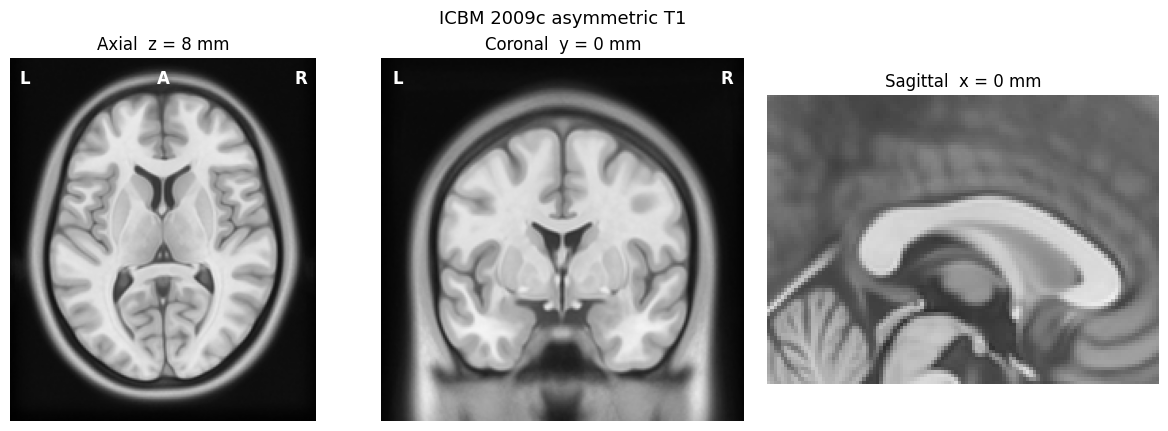

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), layout="constrained")

panels = (
    (axial(vol, 8), "Axial  z = 8 mm"),
    (coronal(vol, 0), "Coronal  y = 0 mm"),
    (sagittal_crop(vol, 0), "Sagittal  x = 0 mm"),
)
for ax, (sl, title) in zip(axes, panels):
    ax.imshow(sl, cmap="gray", vmin=0, vmax=100)
    ax.set_title(title)
    ax.axis("off")

for ax in axes[:2]:
    ax.text(0.03, 0.97, "L", transform=ax.transAxes, color="white",
            fontsize=12, fontweight="bold", va="top")
    ax.text(0.97, 0.97, "R", transform=ax.transAxes, color="white",
            fontsize=12, fontweight="bold", va="top", ha="right")

axes[0].text(0.50, 0.97, "A", transform=axes[0].transAxes, color="white",
             fontsize=12, fontweight="bold", va="top", ha="center")
fig.suptitle("ICBM 2009c asymmetric T1", fontsize=13)
plt.show()

## Mirror subtraction, at a few scales

Asymmetry here is the template minus its left–right mirror. Red means this side is brighter than the voxel across the midline. On a T1, brighter usually means more tissue.

At 0 mm of blur every sulcus that misses its twin draws a ribbon, and the color scale saturates. A few millimetres of blur asks a coarser question: which side has more tissue in this neighborhood? The 8 mm panel is the one to read. Wider than that, the frontal and occipital effects start to bleed into each other.

All four panels share the 8 mm color limit, so the amplitudes are comparable.

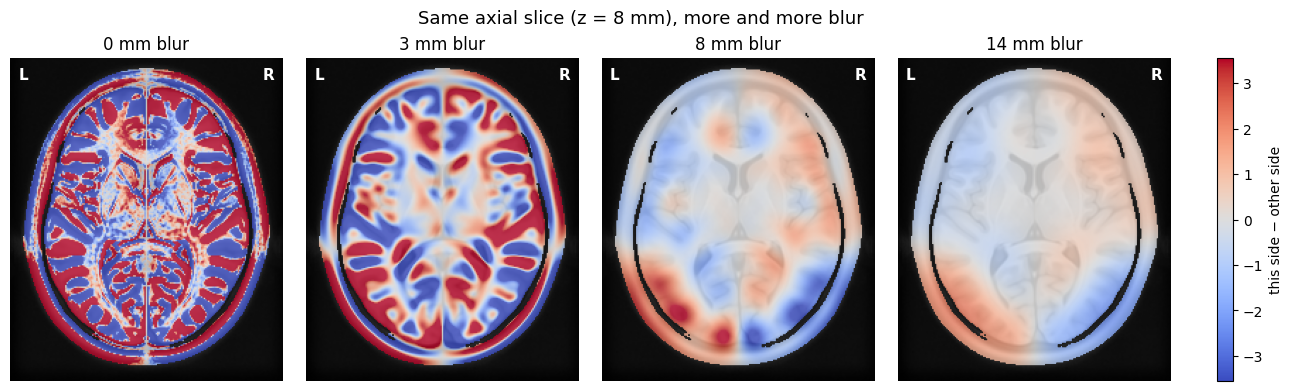

In [3]:
def draw_axial(ax, overlay, z_mm, limit, title):
    ax.imshow(axial(vol, z_mm), cmap="gray", vmin=0, vmax=100)
    shown = np.ma.masked_where(~axial(head, z_mm), axial(overlay, z_mm))
    ax.imshow(shown, cmap="coolwarm", vmin=-limit, vmax=limit, alpha=0.8)
    ax.set_title(title)
    ax.axis("off")
    ax.text(0.03, 0.97, "L", transform=ax.transAxes, color="white",
            fontsize=11, fontweight="bold", va="top")
    ax.text(0.97, 0.97, "R", transform=ax.transAxes, color="white",
            fontsize=11, fontweight="bold", va="top", ha="right")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), layout="constrained")
for ax, sigma in zip(axes, (0, 3, 8, 14)):
    smoothed = gaussian_filter(vol, sigma / zooms)
    draw_axial(ax, smoothed - mirror_lr(smoothed), 8, clim, f"{sigma:.0f} mm blur")

bar = fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-clim, vmax=clim), cmap="coolwarm"),
    ax=axes, fraction=0.046, pad=0.04,
)
bar.set_label("this side − other side")
fig.suptitle("Same axial slice (z = 8 mm), more and more blur", fontsize=13)
plt.show()

## What is asymmetric

On the 8 mm map, at typical axial heights:

- The **right frontal** lobe is brighter than the left. That is the right frontal petalia.
- The **left occipital** lobe is brighter than the right. That is the left occipital petalia.

From above, the cerebrum is slightly twisted: fuller on the right in front, fuller on the left in back. That pair is the Yakovlevian torque. It is a wide, shallow shape, about one percent of tissue intensity, which is why the raw slice looks symmetric.

The same colors run through the middle of the cerebrum and fade toward the vertex. On the coronal row, the frontal cut (y = 40) is brighter on the right and the occipital cut (y = −60) is brighter on the left. y = 0 sits between those two lobes, so both colors are in the frame. The outline of the head barely moves.

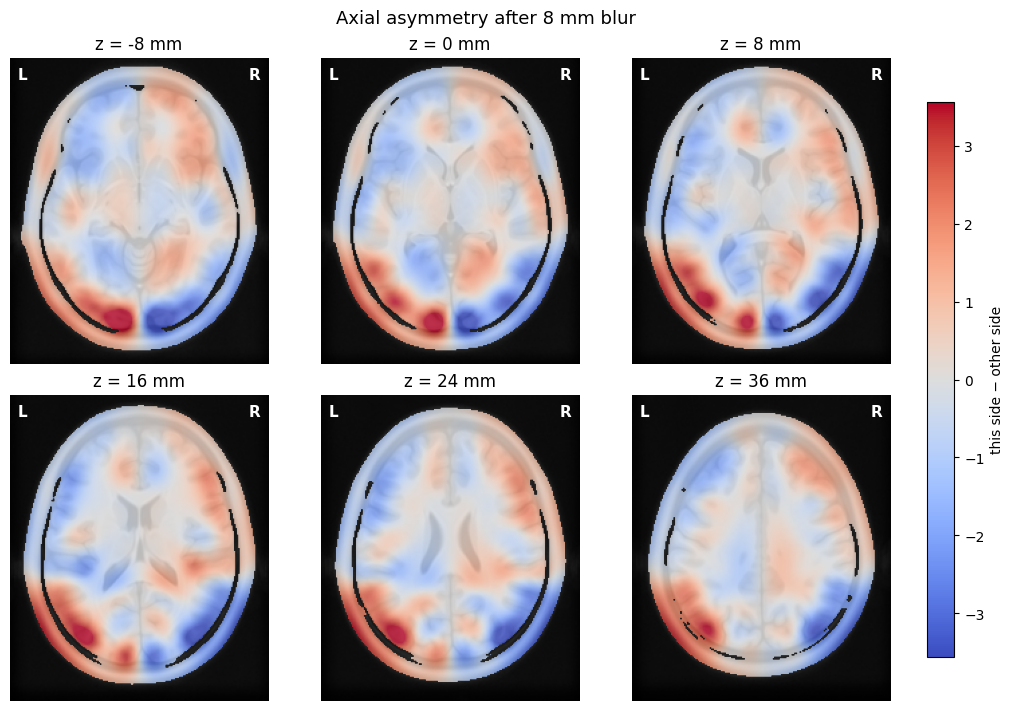

In [4]:
z_slices = (-8, 0, 8, 16, 24, 36)

fig, axes = plt.subplots(2, 3, figsize=(10.5, 7), layout="constrained")
for ax, z_mm in zip(axes.ravel(), z_slices):
    draw_axial(ax, diff, z_mm, clim, f"z = {z_mm:.0f} mm")

bar = fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-clim, vmax=clim), cmap="coolwarm"),
    ax=axes, fraction=0.03, pad=0.04,
)
bar.set_label("this side − other side")
fig.suptitle(f"Axial asymmetry after {SIGMA_MM:.0f} mm blur", fontsize=13)
plt.show()

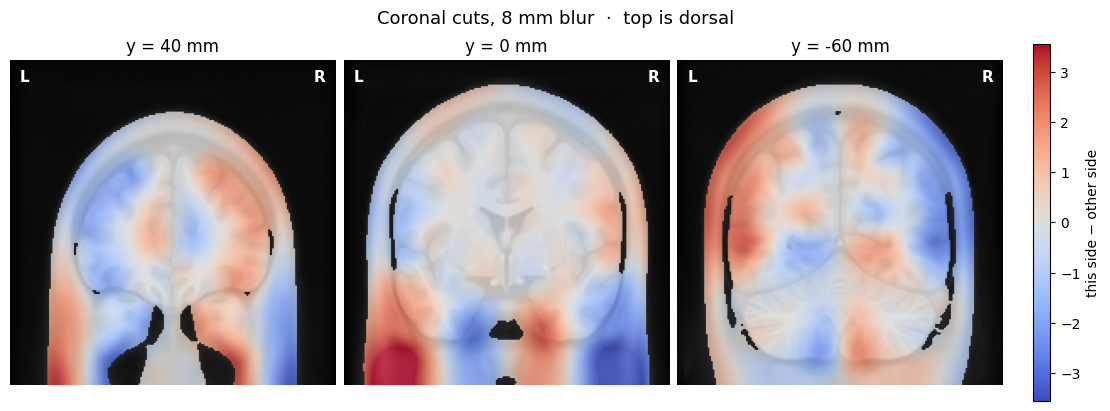

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.0), layout="constrained")
for ax, y_mm in zip(axes, (40, 0, -60)):
    ax.imshow(coronal(vol, y_mm), cmap="gray", vmin=0, vmax=100)
    shown = np.ma.masked_where(~coronal(head, y_mm), coronal(diff, y_mm))
    ax.imshow(shown, cmap="coolwarm", vmin=-clim, vmax=clim, alpha=0.8)
    ax.set_title(f"y = {y_mm:.0f} mm")
    ax.axis("off")
    ax.text(0.03, 0.97, "L", transform=ax.transAxes, color="white",
            fontsize=11, fontweight="bold", va="top")
    ax.text(0.97, 0.97, "R", transform=ax.transAxes, color="white",
            fontsize=11, fontweight="bold", va="top", ha="right")

bar = fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-clim, vmax=clim), cmap="coolwarm"),
    ax=axes, fraction=0.046, pad=0.03,
)
bar.set_label("this side − other side")
fig.suptitle(f"Coronal cuts, {SIGMA_MM:.0f} mm blur  ·  top is dorsal", fontsize=13)
plt.show()

## How large

Means of (left − right) inside tissue, after the same blur. Positive means the left side is brighter. The boxes stay off the midline, where the longitudinal fissure would water the average down.

The frontal and occipital bars are the petalia. The whole-hemisphere bar is a smaller left-brighter offset underneath that twist. The lateral-fissure bar is the local effect the blur is averaging over: that neighborhood is a bit darker on the left.

whole left hemisphere     left−right +0.16   (897691 voxels)
frontal                   left−right -0.76   (92174 voxels)
occipital                 left−right +0.88   (69587 voxels)


lateral fissure           left−right -0.51   (34751 voxels)


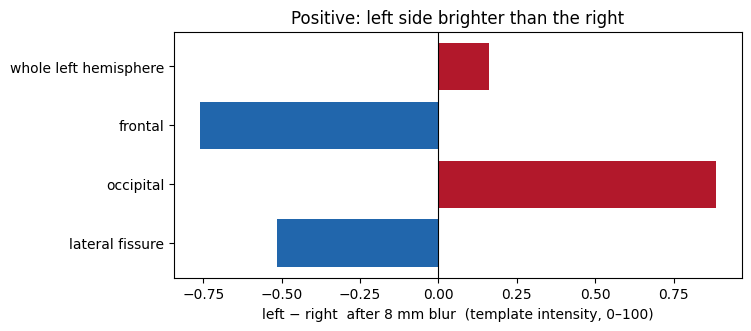

In [6]:
# name, x0, x1, y0, y1, z0, z1   — left hemisphere only, so the mean is left − right
regions = [
    ("whole left hemisphere", -80, -12, -105, 85, -40, 75),
    ("frontal",               -60, -15,   15, 70,  -5, 45),
    ("occipital",             -55, -12,  -95,-45,  -5, 30),
    ("lateral fissure",       -65, -30,  -45, -5,   0, 25),
]

names, values = [], []
for name, x0, x1, y0, y1, z0, z1 in regions:
    mask = (
        tissue
        & (x >= x0) & (x < x1)
        & (y >= y0) & (y < y1)
        & (z >= z0) & (z < z1)
    )
    mu = float(diff[mask].mean())
    names.append(name)
    values.append(mu)
    print(f"{name:24}  left−right {mu:+.2f}   ({int(mask.sum())} voxels)")

fig, ax = plt.subplots(figsize=(7.4, 3.2), layout="constrained")
colors = ["#b2182b" if v > 0 else "#2166ac" for v in values]
ax.barh(names, values, color=colors)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"left − right  after {SIGMA_MM:.0f} mm blur  (template intensity, 0–100)")
ax.set_title("Positive: left side brighter than the right")
plt.show()

## The part the blur throws away

The lateral fissure and the planum temporale are the classic local asymmetry: in most people the left fissure runs longer and flatter, and the left planum is larger. On this average that survives as a small darkening of the left fissure box, not as a clean missing piece of the right hemisphere.

These two sagittal slices go through the insula (x = ±48 mm), with no blur. Dorsal is up, anterior is to the right. The dark cleft running back from the middle of each panel is the lateral fissure. The folds sit in the same place and do not overlie.

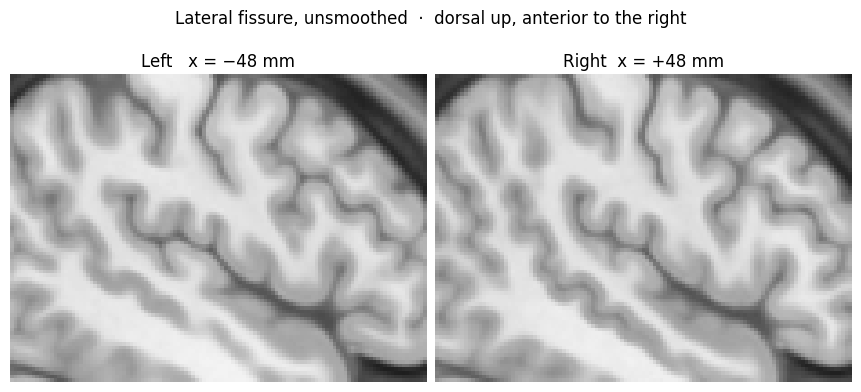

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.2), layout="constrained")
for ax, x_mm, title in (
    (axes[0], -48, "Left   x = −48 mm"),
    (axes[1],  48, "Right  x = +48 mm"),
):
    ax.imshow(sagittal_crop(vol, x_mm), cmap="gray", vmin=0, vmax=100)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("Lateral fissure, unsmoothed  ·  dorsal up, anterior to the right", fontsize=12)
plt.show()

## Reading

The template's natural asymmetry is mostly shape, not outline.

- Right frontal petalia and left occipital petalia (Yakovlevian torque) are the pattern on the blurred map.
- Under that, the left hemisphere is slightly brighter overall.
- Around the lateral fissure the left side is slightly darker, and the unsmoothed folds do not match their twins.

`SIGMA_MM` at the top is the knob. Re-run from the load cell after changing it. The axial heights are `z_slices`.